# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torchvision import datasets
from torchvision import transforms as tfs

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from _bootstrap import setup
from src.vasijas.reporting import ProcessingReport

In [2]:
# Configuración general
PATHS = setup()
report = ProcessingReport()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 32
EPOCHS = 12
LR = 1e-3

IMG_SIZE = 224

FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.)
ROTATION_DEGREES = (0, 15)
PIXEL_FILL = (255, 255, 255)

SEED = 42

DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_NAME = "resnet18"

print("Device:", DEVICE)

Device: cpu


In [3]:
# Transformaciones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
    # tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transforms = val_transforms


class TransformSubset(Dataset):
    """Subset por indices que aplica transform al vuelo."""

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]  # x es PIL si dataset base no tiene transform
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# a) Dataset base SIN transformaciones
full_dataset = datasets.ImageFolder(DATA_DIR)

indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# train vs temp
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# val vs test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

train_dataset = TransformSubset(full_dataset, train_idx, transform=train_transforms)
val_dataset = TransformSubset(full_dataset, val_idx, transform=val_transforms)
test_dataset = TransformSubset(full_dataset, test_idx, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

print("Clases:", class_names)
print(f"Split -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")

Clases: ['clase01', 'clase02', 'clase03', 'clase04', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Split -> train: 756, val: 162, test: 163


In [4]:
from torchvision.models import ResNet18_Weights


# 3. Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


# Modelo (reemplaza rama resnet18 en get_model)
def get_model(model_name, num_classes):
    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT  # equivalente a IMAGENET1K_V1
        model = models.resnet18(weights=weights, progress=True)

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights="IMAGENET1K_V1")
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Modelo no soportado")

    return model.to(DEVICE)


model = get_model(MODEL_NAME, NUM_CLASSES)

In [5]:
from sklearn.utils.class_weight import compute_class_weight

# Pesos por clase (solo train)
classes = np.arange(NUM_CLASSES)
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels,  # etiquetas del split de entrenamiento
)

class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)

# Loss ponderada
criterion = nn.CrossEntropyLoss(weight=class_weights)

# (opcional) inspección
for i, w in enumerate(class_weights_np):
    print(f"{i} - {class_names[i]}: {w:.4f}")

# Optimizador (ajusta para entrenar solo lo descongelado)
optimizer = optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc


def validate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc, all_preds, all_labels

0 - clase01: 3.8182
1 - clase02: 2.1477
2 - clase03: 1.3745
3 - clase04: 9.8182
4 - clase05: 1.7622
5 - clase06: 1.9091
6 - clase07: 2.0214
7 - clase08: 0.3506
8 - clase09: 4.9091
9 - clase10: 0.2771
10 - clase11: 0.8381


In [6]:
# 6. Loop de entrenamiento
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, preds, labels = validate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch 1/12
Train Loss: 2.2235 | Train Acc: 0.2937
Val Loss: 2.2438 | Val Acc: 0.2284
Epoch 2/12
Train Loss: 1.6948 | Train Acc: 0.6138
Val Loss: 1.8532 | Val Acc: 0.6914
Epoch 3/12
Train Loss: 1.4166 | Train Acc: 0.7209
Val Loss: 1.4041 | Val Acc: 0.7593
Epoch 4/12
Train Loss: 1.2288 | Train Acc: 0.7447
Val Loss: 1.2389 | Val Acc: 0.7901
Epoch 5/12
Train Loss: 1.1330 | Train Acc: 0.7897
Val Loss: 1.0563 | Val Acc: 0.7963
Epoch 6/12
Train Loss: 0.9711 | Train Acc: 0.8294
Val Loss: 0.9954 | Val Acc: 0.7840
Epoch 7/12
Train Loss: 0.9167 | Train Acc: 0.8267
Val Loss: 0.9522 | Val Acc: 0.8395
Epoch 8/12
Train Loss: 0.8300 | Train Acc: 0.8254
Val Loss: 1.0306 | Val Acc: 0.8704
Epoch 9/12
Train Loss: 0.7587 | Train Acc: 0.8320
Val Loss: 0.9132 | Val Acc: 0.8580
Epoch 10/12
Train Loss: 0.7365 | Train Acc: 0.8280
Val Loss: 0.9029 | Val Acc: 0.8333
Epoch 11/12
Train Loss: 0.7070 | Train Acc: 0.8413
Val Loss: 0.7816 | Val Acc: 0.8395
Epoch 12/12
Train Loss: 0.6818 | Train Acc: 0.8439
Val Loss: 0.

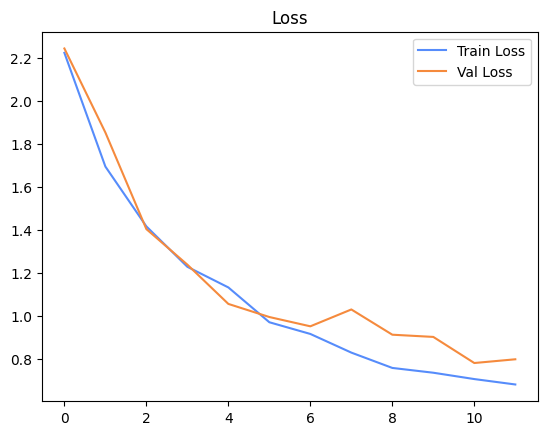

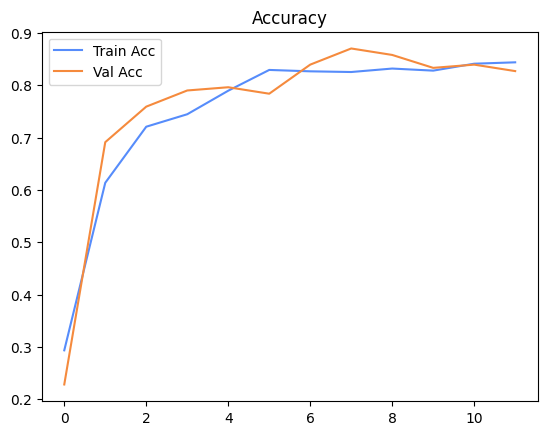

In [7]:
# 7. Curvas de entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.8098
              precision    recall  f1-score   support

     clase01       1.00      0.50      0.67         4
     clase02       0.75      0.43      0.55         7
     clase03       0.77      0.91      0.83        11
     clase04       0.00      0.00      0.00         1
     clase05       0.89      0.89      0.89         9
     clase06       0.40      0.57      0.47         7
     clase07       0.86      0.86      0.86         7
     clase08       0.89      0.81      0.85        42
     clase09       0.20      0.67      0.31         3
     clase10       0.98      0.83      0.90        54
     clase11       0.75      1.00      0.86        18

    accuracy                           0.81       163
   macro avg       0.68      0.68      0.65       163
weighted avg       0.85      0.81      0.82       163



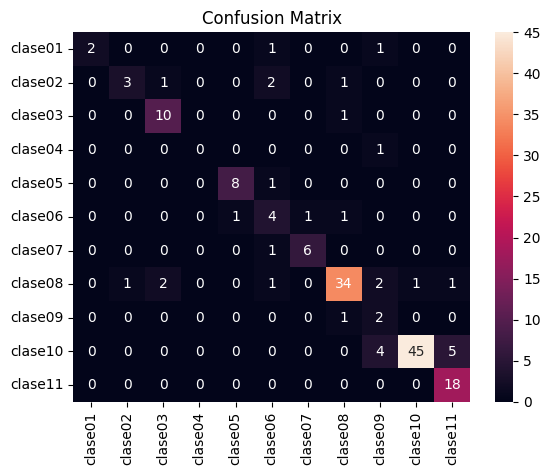

In [8]:
# 8. Evaluación final
_, test_acc, final_preds, final_labels = validate(model, test_loader)
print(f"Test Acc: {test_acc:.4f}")

all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [9]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final2.pth")